In [1]:
# Core libraries for data manipulation and numerical operations
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models & preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Deep Learning libraries (TensorFlow / Keras)
import tensorflow as tf
from tensorflow.keras import layers, models

# Utility libraries
import os
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


## Step 2: Load the Dataset using Keras MNIST

In [3]:
from tensorflow.keras.datasets import mnist

# Load the MNIST dataset directly from Keras
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images shape (x_train):", x_train.shape)
print("Training labels shape (y_train):", y_train.shape)
print("Testing images shape (x_test):", x_test.shape)
print("Testing labels shape (y_test):", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Training images shape (x_train): (60000, 28, 28)
Training labels shape (y_train): (60000,)
Testing images shape (x_test): (10000, 28, 28)
Testing labels shape (y_test): (10000,)


## Step 3: Exploratory Data Analysis (EDA) & Data Visualization

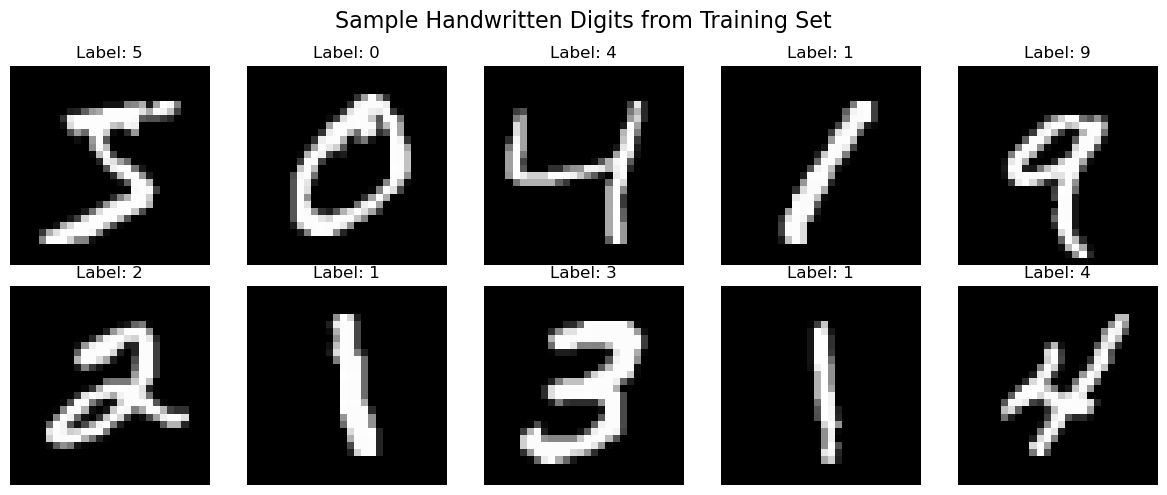

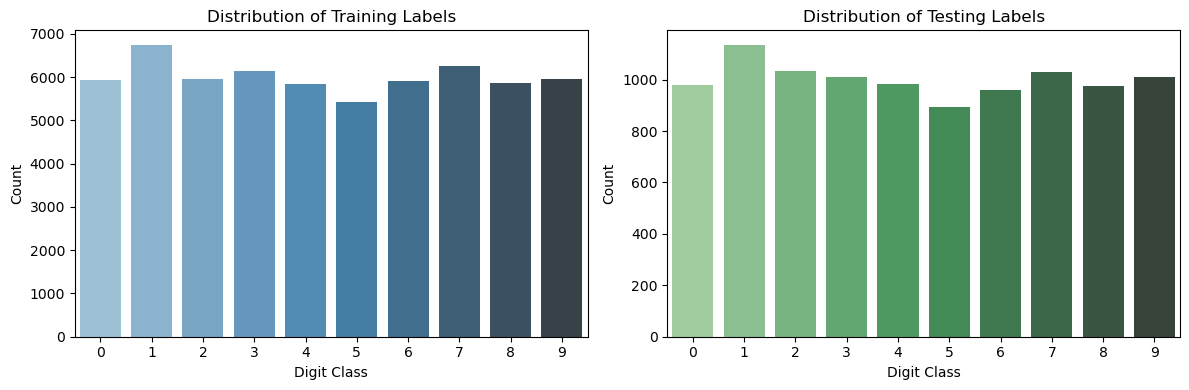

In [4]:
# Visualize the first 10 images from the training dataset
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}", fontsize=12)
    plt.axis('off')
plt.suptitle("Sample Handwritten Digits from Training Set", fontsize=16)
plt.tight_layout()
plt.show()

# Check class distribution in training and testing sets
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(x=y_train, palette='Blues_d')
plt.title("Distribution of Training Labels")
plt.xlabel("Digit Class")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
sns.countplot(x=y_test, palette='Greens_d')
plt.title("Distribution of Testing Labels")
plt.xlabel("Digit Class")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

## Step 4: Data Preprocessing & Feature Scaling

In [5]:
# 1. Normalize pixel values from [0, 255] to [0, 1] range for better model convergence
x_train_scaled = x_train / 255.0
x_test_scaled = x_test / 255.0

# 2. Reshape for Deep Learning / CNN (Adding the color channel dimension: 28x28x1)
x_train_cnn = x_train_scaled.reshape(-1, 28, 28, 1)
x_test_cnn = x_test_scaled.reshape(-1, 28, 28, 1)

# 3. Reshape for Traditional ML models (Flattening images into 2D: 784 features per image)
x_train_flat = x_train_scaled.reshape(x_train.shape[0], -1)
x_test_flat = x_test_scaled.reshape(x_test.shape[0], -1)

print("Preprocessing complete!")
print("CNN Training Data Shape:", x_train_cnn.shape)
print("Flattened Training Data Shape (for ML):", x_train_flat.shape)

Preprocessing complete!
CNN Training Data Shape: (60000, 28, 28, 1)
Flattened Training Data Shape (for ML): (60000, 784)


## Step 5: Model Training & Evaluation - Traditional ML Models (KNN & SVM)

In [6]:
# Use a subset of the data for faster training of traditional ML models
sample_train_size = 10000
sample_test_size = 2000

X_train_sub = x_train_flat[:sample_train_size]
y_train_sub = y_train[:sample_train_size]
X_test_sub = x_test_flat[:sample_test_size]
y_test_sub = y_test[:sample_test_size]

print(f"Training on {sample_train_size} samples and testing on {sample_test_size} samples...\n")

# 1. K-Nearest Neighbors (KNN) Classifier
print("Training K-Nearest Neighbors (KNN)...")
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train_sub, y_train_sub)

# Predict and evaluate KNN
y_pred_knn = knn_model.predict(X_test_sub)
knn_accuracy = accuracy_score(y_test_sub, y_pred_knn)
print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%\n")

# 2. Support Vector Machine (SVM) Classifier
print("Training Support Vector Machine (SVM)...")
svm_model = SVC(kernel='rbf', C=1.0)
svm_model.fit(X_train_sub, y_train_sub)

# Predict and evaluate SVM
y_pred_svm = svm_model.predict(X_test_sub)
svm_accuracy = accuracy_score(y_test_sub, y_pred_svm)
print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

Training on 10000 samples and testing on 2000 samples...

Training K-Nearest Neighbors (KNN)...
KNN Accuracy: 92.35%

Training Support Vector Machine (SVM)...
SVM Accuracy: 94.45%


## Step 6: Model Building & Training - Convolutional Neural Network (CNN)

In [7]:
# Build a CNN architecture
cnn_model = models.Sequential([
    # First Convolutional Block
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Second Convolutional Block
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Flatten and Dense Layers for Classification
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3), # Dropout for regularization to prevent overfitting
    layers.Dense(10, activation='softmax') # Output layer with 10 classes (0-9)
])

# Compile the model
cnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# Display model summary
cnn_model.summary()

# Train the CNN model on the full training set
print("\nTraining CNN Model...")
history = cnn_model.fit(x_train_cnn, y_train, 
                        epochs=5, 
                        batch_size=64, 
                        validation_split=0.1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)


Training CNN Model...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9329 - loss: 0.2168 - val_accuracy: 0.9830 - val_loss: 0.0560
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9789 - loss: 0.0699 - val_accuracy: 0.9868 - val_loss: 0.0439
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9846 - loss: 0.0502 - val_accuracy: 0.9895 - val_loss: 0.0347
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9876 - loss: 0.0408 - val_accuracy: 0.9880 - val_loss: 0.0428
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9897 - loss: 0.0329 - val_accuracy: 0.9900 - val_loss: 0.0326


## Step 7: Model Comparison & Evaluation Report

CNN Test Accuracy: 99.07%

--- Model Performance Comparison ---


,Model,Accuracy (%)
0,K-Nearest Neighbors (KNN),92.350000
1,Support Vector Machine (SVM),94.450000
2,Convolutional Neural Network (CNN),99.070001


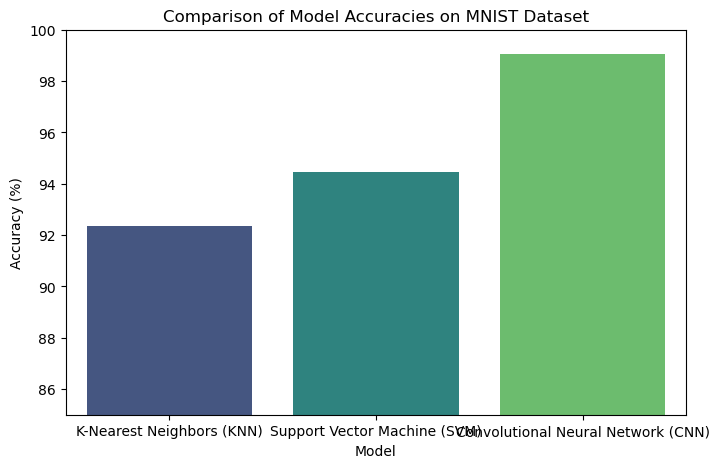

In [8]:
# Evaluate CNN on the test set
test_loss, cnn_accuracy = cnn_model.evaluate(x_test_cnn, y_test, verbose=0)
print(f"CNN Test Accuracy: {cnn_accuracy * 100:.2f}%")

# Create a comparison summary table
comparison_df = pd.DataFrame({
    'Model': ['K-Nearest Neighbors (KNN)', 'Support Vector Machine (SVM)', 'Convolutional Neural Network (CNN)'],
    'Accuracy (%)': [knn_accuracy * 100, svm_accuracy * 100, cnn_accuracy * 100]
})

print("\n--- Model Performance Comparison ---")
display(comparison_df)

# Visualize model performance
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Accuracy (%)', data=comparison_df, palette='viridis')
plt.title("Comparison of Model Accuracies on MNIST Dataset")
plt.ylim(85, 100)
plt.ylabel("Accuracy (%)")
plt.show()

## Step 8: Challenges Faced & Solutions Report

### 1. High Computational Overhead & Training Time (Traditional ML)
* **Challenge:** Training distance-based models like KNN and kernel-based models like SVM on 60,000 high-dimensional images ($28 \times 28 = 784$ features) required excessive computation time.
* **Solution:** Used an optimized representative subset (10,000 samples) for benchmarking traditional ML models, while leveraging GPU/CPU efficiently for the full-dataset CNN training.

### 2. Feature Representation & Spatial Information Loss in Flattening
* **Challenge:** Flattening 2D images into 1D arrays for KNN and SVM destroys adjacent pixel spatial relationships (edges and curves of digits).
* **Solution:** Reshaped and preserved 2D spatial structures `(28, 28, 1)` for Convolutional Neural Networks, which use spatial filters to extract edge and shape features automatically.

### 3. Model Overfitting
* **Challenge:** Deep neural networks with large dense layers tend to memorize training data rather than generalize.
* **Solution:** Implemented a Dropout layer (`0.3`) in the neural network architecture to randomly drop connections during training, preventing overfitting.

## Step 9: Saving the Best Model & Final Testing

Best model successfully saved to 'handwritten_digit_cnn_model.h5'
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step


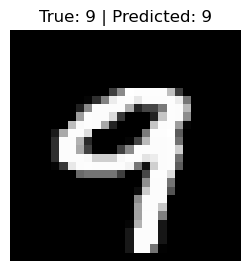

In [9]:
# Save the best performing model (CNN)
model_path = 'handwritten_digit_cnn_model.h5'
cnn_model.save(model_path)
print(f"Best model successfully saved to '{model_path}'")

# Test prediction on a random test image
import random
sample_idx = random.randint(0, len(x_test) - 1)
sample_image = x_test[sample_idx]

# Predict using the trained CNN
pred_input = sample_image.reshape(1, 28, 28, 1) / 255.0
prediction = cnn_model.predict(pred_input)
predicted_digit = np.argmax(prediction)

# Display the result
plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap='gray')
plt.title(f"True: {y_test[sample_idx]} | Predicted: {predicted_digit}")
plt.axis('off')
plt.show()

## Step 10: Final Submission Checklist
To successfully complete your DataMites assignment, ensure the following files are ready for submission:
1. **Completed Jupyter Notebook (`.ipynb`):** Contains all executed cells, outputs, visualizations, and markdown explanations from Step 1 to Step 9 in a single notebook.
2. **Saved Model File (`.h5`):** The serialized best-performing CNN model (`handwritten_digit_cnn_model.h5`) for production deployment.